# Predicting homicide case outcomes (SAS)

The code is the same as `Predicting_Murder.sas`, cut into sections. The results shown under the cells are taken from the report, not from a fresh run: charts are the images from the report and tables are copied from it. The SAS code runs on the Murder Accountability Project data, which is not included here.

## Import the data

In [ ]:
*import homicide data;
data AMA3011.SHR;
    length 
        ID $16
        CNTYFIPS $10
        Ori $10
        State $20
        Agency $15
        Agentype $20
        Source $3
        Solved $3
        Month $3
        ActionType $15
        Homicide $40
        Situation $35
        VicSex $1
        VicRace $35
        VicEthnic $22
        OffSex $1
        OffRace $35
        OffEthnic $22
        Weapon $35
        Relationship $30
        Circumstances $35
        Subcircumstances $50
        MSA $10
    ;
    infile "/home/u64128910/AMA3011/SHR65_23.csv" dsd firstobs=2 dlm=',' missover;
    input 
        ID $ 
        CNTYFIPS $ 
        Ori $ 
        State $ 
        Agency $ 
        Agentype $ 
        Source $ 
        Solved $ 
        Year 
        Month $ 
        Incident 
        ActionType $ 
        Homicide $ 
        Situation $ 
        VicAge 
        VicSex $ 
        VicRace $ 
        VicEthnic $ 
        OffAge 
        OffSex $ 
        OffRace $ 
        OffEthnic $ 
        Weapon $ 
        Relationship $ 
        Circumstances $ 
        Subcircumstances $ 
        VicCount 
        OffCount 
        FileDate 
        MSA $ 
    ;
run;

## Clean the data

In [ ]:
*Remove rows where victim sex is unknown;
data AMA3011.SHR;
    set AMA3011.SHR;
    if VicSex = 'U' then delete;
run;

*Replace 999 values in age variables with missing values;
data AMA3011.SHR;
    set AMA3011.SHR;
    if VicAge = 999 then delete;
    if OffAge = 999 then OffAge = '.';
run;

Rows before cleaning: 894,636
Removed: victim sex 'Unknown' (0.01%) and victim age 999 (1.3%)
Rows after cleaning: 880,928


## Summary statistics and frequencies

In [ ]:
*Generate summary statistics for numeric variables;
proc means data=AMA3011.SHR n nmiss mean std min max median q1 q3 maxdec=2;
    title "Basic Summary Statistics for All Numeric Variables";
run;

*Generate frequency tables for variables;
proc freq data=AMA3011.SHR;
    tables VicSex;
    title "Frequency Distribution of Victim Sex";
run;
proc freq data=AMA3011.SHR;
    tables VicAge;
    title "Frequency Distribution of Victim Age";
run;
proc freq data=AMA3011.SHR;
    tables Weapon;
    title "Frequency Distribution of Weapons Used";
run;
proc freq data=AMA3011.SHR;
    tables VicRace;
    title "Frequency Distribution of Victim Race";
run;

## Victim age groups

In [ ]:
*Create age groups for victims;
data AMA3011.SHRv1;
    set AMA3011.SHR;
    length VicAgeGroup $10;
    if VicAge <= 5 then VicAgeGroup = "0-5";
    else if VicAge <= 14 then VicAgeGroup = "06-14";
    else if VicAge <= 18 then VicAgeGroup = "15-18";
    else if VicAge <= 29 then VicAgeGroup = "19-29";
    else if VicAge <= 39 then VicAgeGroup = "30-39";
    else if VicAge <= 49 then VicAgeGroup = "40-49";
    else if VicAge <= 59 then VicAgeGroup = "50-59";
    else if VicAge <= 69 then VicAgeGroup = "60-69";
    else if VicAge >= 70 then VicAgeGroup = "70+";
run;

*Plot the number of victims in each age bracket;
proc sgplot data=AMA3011.SHRv1;
    vbar VicAgeGroup;
    xaxis label="Age Group";
    yaxis label="Number of Victims";
    title "Number of Victims by Age Range";
run;
*Plot the percentage of victims in each age bracket;
proc sgplot data=AMA3011.SHRv1;
    vbar VicAgeGroup /
    stat=percent;
    xaxis label="Age Group";
    yaxis label="Percentage of Victims";
    title "Percentage of Victims by Age Range";
run;

## Overall solve rate

In [ ]:
*Convert solved status to binary numeric variable;
data AMA3011.SHRv2;
    set AMA3011.SHRv1;
    if Solved = 'Yes' then solvedNumeric = 1;
    else if Solved = 'No' then solvedNumeric = 0;
    else solvedNumeric = .;
run;

*Calculate overall solve rate;
proc means data=AMA3011.SHRv2 mean n;
    var solvedNumeric;
    format solvedNumeric percent8.2;
    title "Overall Homicide Solve Rate";
run;

*Binomial CI;
proc freq data=AMA3011.SHRv2;
    tables solvedNumeric / binomial(level='1');
    title "Solve Rate with Binomial Confidence Interval";
run;

Solved: 625,679 of 880,928 (71%)
95% confidence interval: 70.9% to 71.1%


## Solve rates by age group and victim sex

In [ ]:
*Find solve rates within different age brackets;
proc means data=AMA3011.SHRv2;
    class VicAgeGroup;
    var solvedNumeric;
    output out=solveRates_age mean=ovrsolveRate n=count;
    title "Solve Rates by Victim Age Group";
run;

*Test difference in solve rates between different age groups;
proc freq data=AMA3011.SHRv1;
    tables VicAgeGroup*Solved / chisq expected nocol nopercent;
    title "Chi-Squared Test: Solve Rates by Age Group";
run;

*Find solve rates for each gender;
proc means data=AMA3011.SHRv2;
    class VicSex;
    var solvedNumeric;
    where VicSex in ('M', 'F');
    output out=sex_solve_rates n=Total_Cases sum=Cases_Solved mean=Solve_Rate;
    title "Solve Rates by Victim Sex";
run;

*Test difference in solve rates between male and female victims;
proc ttest data=AMA3011.SHRv2;
    class VicSex;
    var solvedNumeric;
    where VicSex in ('M', 'F');
    title "T-Test: Solve Rate Difference by Victim Sex";
run;



*Graph showing solve rates for each age group;
proc sgplot data=solveRates_age;
    vbar VicAgeGroup / response=ovrsolveRate;
    xaxis label="Age Group";
    yaxis label="Fraction of Cases Solved" values=(0 to 1 by 0.1);
    title "Fraction of Homicides Solved by Victim Age Group";
run;

Victim sex: 77.7% male (n = 684,299), 22.3% female (n = 196,629)
Solve rate: 78.6% female, 68.9% male (p < 0.001)


## Weapon categories

In [ ]:
*Group weapons into categories;
data AMA3011.SHRv3;
    set AMA3011.SHRv2;
    length WeaponCategory $25;
    
    select (Weapon);
        when ('Handgun - pistol, revolver, etc', 'Rifle', 'Shotgun', 
              'Firearm, type not stated', 'Other gun') 
            WeaponCategory = 'Firearms';
        when ('Knife or cutting instrument') 
            WeaponCategory = 'Knife or cutting instrument';
        when ('Blunt object - hammer, club, etc', 'Personal weapons, includes beating') 
            WeaponCategory = 'Blunt Force';
        when ('Asphyxiation - includes death by ga', 'Strangulation - hanging', 'Drowning') 
            WeaponCategory = 'Asphyxiation';        
        when ('Fire', 'Explosives') 
            WeaponCategory = 'Fire/Explosives';                  
        when ('Other or type unknown', 'Weapon Not Reported','Pushed or thrown out window',
              'Narcotics or drugs, sleeping pills', 'Poison - does not include gas') 
            WeaponCategory = 'Other/Unknown';       
        otherwise WeaponCategory = 'Other/Unknown';
    end;
run;

*Plot the percentage of victims by Weapon Category;
proc sgplot data=AMA3011.SHRv3;
    vbar WeaponCategory /
    stat=percent;
    xaxis label="Weapon Category";
    yaxis label="Percentage of Victims";
    title "Percentage of Victims by Weapon Category";
run;

* Find the solve rate for each Weapon Category;
proc means data=AMA3011.SHRv3;
    class WeaponCategory;
    var solvedNumeric;
    output out=solveRates_wc mean=ovrsolveRate n=count;
    title "Solve Rates by Weapon Category";
run;

* Plot the solve rates for different weapon categories;
proc sgplot data=solveRates_wc;
    vbar WeaponCategory / response=ovrsolveRate;
    xaxis label="Weapon Category";
    yaxis label="Fraction of Cases Solved" values=(0 to 1 by 0.1);
    title "Fraction of Homicides Solved by Weapon Category";
run;

Category          n        % of cases
Firearms          592,368  67.24%
Knife/Cutting     123,317  14.00%
Blunt Force        85,041   9.66%
Asphyxiation       16,670   1.89%
Fire/Explosives     8,560   0.97%
Other/Unknown      54,972   6.24%


## Solve rates by state

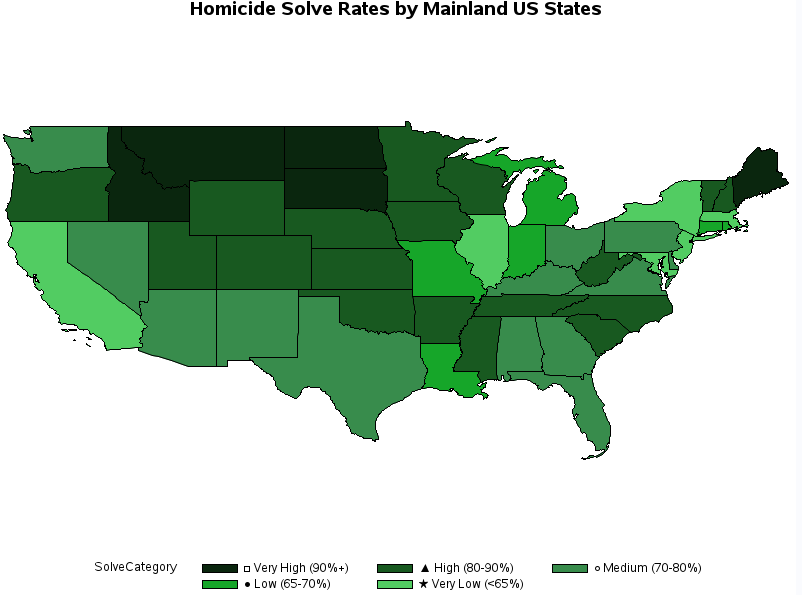

Solve rates range from 39.7% (District of Columbia) to 93.0% (South Dakota)


In [ ]:
*Find the solve rate for each state;
proc means data=AMA3011.SHRv3;
    class State;
    var solvedNumeric;
    output out=solveRates_state mean=ovrsolveRate n=count;
    title "Solve Rates by State";
run;
*Import the shape file;
proc mapimport out=usStatesMap datafile='/home/u64128910/AMA3011/cb_2018_us_state_20m.shp';
run;
*Make state names consistent;
data solveRates_stateCorrected;
    set solveRates_state;
    if State = 'Rhodes Island' then State = 'Rhode Island';
run;
proc sql;
    create table map_data as
    select a.*, b.ovrsolveRate
    from usStatesMap as a
    left join solveRates_stateCorrected as b
    on a.NAME = b.State;
quit;
*Remove non-mainland states;
data mainland_only;
    set map_data;
    where NAME not in ('Puerto Rico','Alaska','Hawaii');
run;
data mainland_categorised;
    set mainland_only;
    length SolveCategory $20;
    
     if ovrsolveRate >= 0.90 then SolveCategory = "□ Very High (90%+)";
    else if ovrsolveRate >= 0.80 then SolveCategory = "▲ High (80-90%)";
    else if ovrsolveRate >= 0.70 then SolveCategory = "○ Medium (70-80%)";
    else if ovrsolveRate >= 0.65 then SolveCategory = "● Low (65-70%)";
    else SolveCategory = "★ Very Low (<65%)";
run;

* Create choropleth map of solve rates by state;
proc gmap map=usStatesMap data=mainland_categorised;
   id NAME;
   pattern1 color='CX0A260E' v=s ;
   pattern2 color='CX185920' v=s;
   pattern3 color='CX388C4C' v=s;
   pattern4 color='CX16A629' v=s;
   pattern5 color='CX52CC62' v=s;
   choro SolveCategory / discrete;
   title "Homicide Solve Rates by Mainland US States";
run;
quit;

## Solve rates by population density

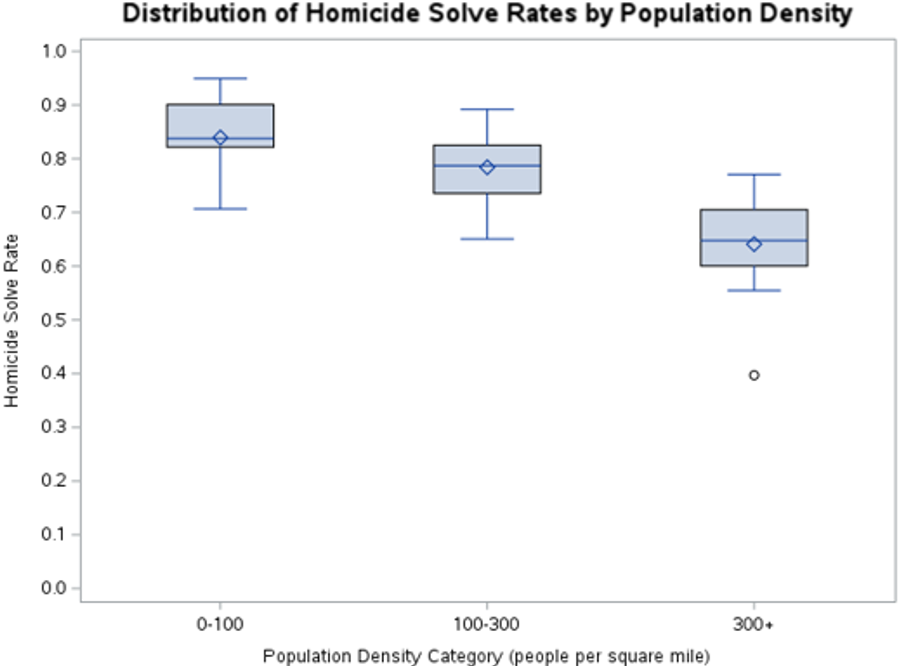

One-way ANOVA across the three density groups: F(2,47) = 25.04, p < 0.001


In [ ]:
*Categorise states by population density;
data state_categorised;
    set state_solve_rates;
    length ppsqmi $25;
    *High Density (>300 ppsm);
    if State in ('District of Columbia', 'New Jersey', 'Rhode Island', 
                 'Massachusetts', 'Connecticut', 'Maryland', 'Delaware',
                 'New York', 'Florida', 'Ohio', 'Pennsylvania', 'California',
                 'Illinois') 
       then ppsqmi = '300+';
    *Medium Density (100-300 ppsm);
    else if State in ('North Carolina', 'Virginia', 'Georgia', 'Indiana',
                     'South Carolina', 'Michigan', 'Tennessee', 'New Hampshire',
                     'Washington', 'Texas', 'Kentucky', 'Wisconsin', 'Louisiana',
                     'Alabama', 'Missouri', 'West Virginia', 'Minnesota', 'Vermont')
       then ppsqmi = '100-300';
    *Low Density (<100 ppsm);
    else ppsqmi = '0-100';
run;
*Visualise solve rate distribution by population density;
proc sgplot data=state_categorised;
    vbox ovrsolveRate / category=ppsqmi;
    xaxis label="Population Density Category (people per square mile)";
    yaxis label="Homicide Solve Rate" values=(0 to 1 by 0.1);
    title "Distribution of Homicide Solve Rates by Population Density";
run;
*Test differences in solve rates across density categories;
proc anova data=state_categorised;
    class ppsqmi;
    model ovrsolveRate = ppsqmi;
    means ppsqmi;
    title "Solve Rate Differences by Population Density (People per Square Mile)";
run;

*Add population density categories to main dataset;
data AMA3011.SHRv3;
    set AMA3011.SHRv3;
    length ppsqmi $25;
    *High Density (>300 ppsm);
    if State in ('District of Columbia', 'New Jersey', 'Rhode Island', 
                 'Massachusetts', 'Connecticut', 'Maryland', 'Delaware',
                 'New York', 'Florida', 'Ohio', 'Pennsylvania', 'California',
                 'Illinois') 
       then ppsqmi = '300+';
    *Medium Density (100-300 ppsm);
    else if State in ('North Carolina', 'Virginia', 'Georgia', 'Indiana',
                     'South Carolina', 'Michigan', 'Tennessee', 'New Hampshire',
                     'Washington', 'Texas', 'Kentucky', 'Wisconsin', 'Louisiana',
                     'Alabama', 'Missouri', 'West Virginia', 'Minnesota', 'Vermont')
       then ppsqmi = '100-300';
    *Low Density (<100 ppsm);
    else ppsqmi = '0-100';
run;

## Solve rates by race over time

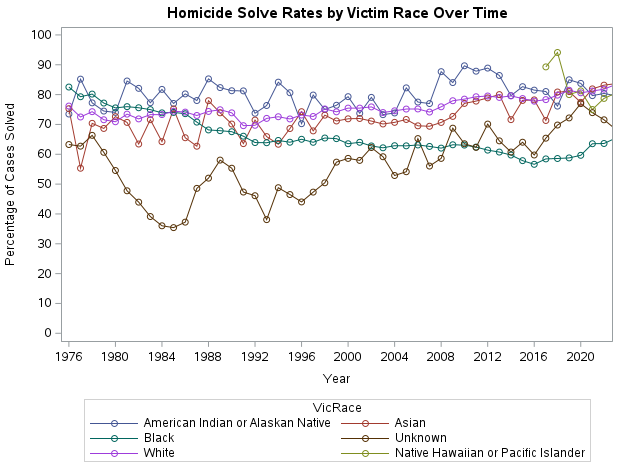

In [ ]:
* Analyse homicide solve rates by race over time;
proc means data=AMA3011.SHRv3 noprint;
    class Year vicRace;
    var solvedNumeric;
    output out=raceSolveRates mean=SolveRate n=Count;
run;
data raceSolveRates;
    set raceSolveRates;
    SolvePercent = SolveRate * 100;
run;
* Plot solve rates by race over time;
proc sgplot data=raceSolveRates;
    where _TYPE_ = 3; 
    series x=Year y=SolvePercent / group=vicRace markers;
    xaxis label="Year" integer values=(1976 to 2023 by 2);
    yaxis label="Percentage of Cases Solved" values=(0 to 100 by 10);
    title "Homicide Solve Rates by Victim Race Over Time";
run;

## Solve rates by weapon type over time

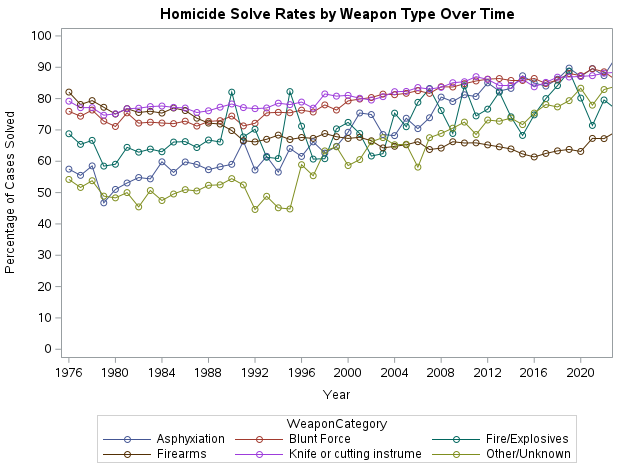

In [ ]:
*Analyse homicide solve rates by weapon type over time;
proc means data=AMA3011.SHRv3 noprint;
    class Year WeaponCategory;
    var solvedNumeric;
    output out=WeaponSolveRates mean=SolveRate n=Count;
run;
data WeaponSolveRates;
    set WeaponSolveRates;
    SolvePercent = SolveRate * 100;
run;
*Plot solve rates by weapon type over time;
proc sgplot data=WeaponSolveRates;
    where _TYPE_ = 3; 
    series x=Year y=SolvePercent / group=WeaponCategory markers;
    xaxis label="Year" integer values=(1976 to 2023 by 2);
    yaxis label="Percentage of Cases Solved" values=(0 to 100 by 10);
    title "Homicide Solve Rates by Weapon Type Over Time";
run;

## Overall trends by year

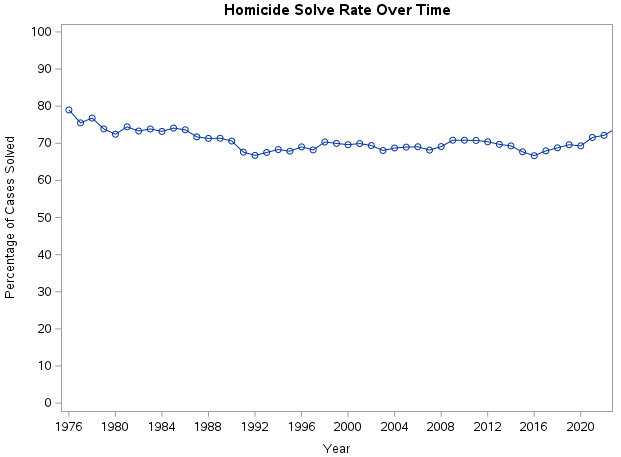

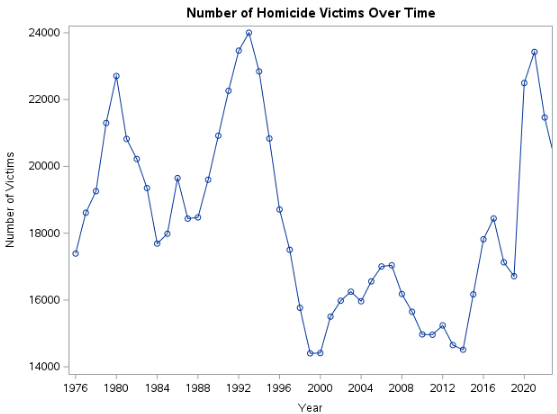

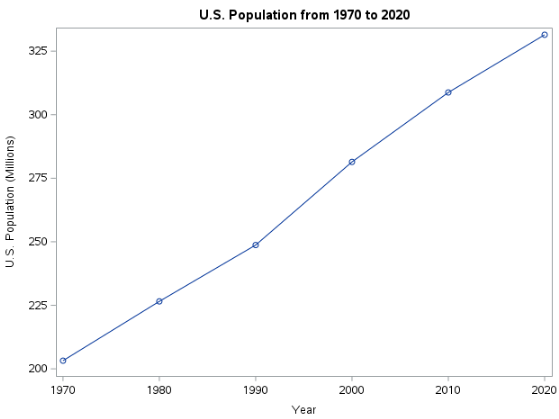

In [ ]:
*Calculate overall solve rates by year;
proc means data=AMA3011.SHRv3;
    class Year;
    var solvedNumeric;
    output out=overallVictimsRate mean=SolveRate n=Count;
    title "Overall Homicide Trends by Year";
run;
*Plot solve rate by year;
proc sgplot data=overallVictimsRate;
    series x=Year y=SolvePercent / markers;
    xaxis label="Year" integer values=(1976 to 2023 by 2);
    yaxis label="Percentage of Cases Solved" values=(0 to 100 by 10);
    title "Homicide Solve Rate Over Time";
run;
*Plot number of victims over time;
proc sgplot data=overallVictimsRate;
    series x=Year y=Count / markers;
    xaxis label="Year" integer values=(1976 to 2023 by 2);
    yaxis label="Number of Victims" 
          values=(14000 16000 18000 20000 22000 24000);
    title "Number of Homicide Victims Over Time";
run;
* Create population data for visualisation;
data populationData;
    input Year US_Population;
    datalines;
1970 203.211926
1980 226.545805
1990 248.709873
2000 281.421906
2010 308.745538
2020 331.449281
;
run;
* Plot U.S. population over time;
proc sgplot data=populationData;
    series x=Year y=US_Population / markers;
    xaxis label="Year" integer values=(1970 to 2020 by 10);
    yaxis label="U.S. Population (Millions)";
    title "U.S. Population from 1970 to 2020";
run;

## Logistic regression: split and fit

In [ ]:
*LOGISTIC REGRESSION;

* Split data into training and testing sets;
proc surveyselect data=AMA3011.SHRv3 method=srs samprate=0.7 out=AllData outall;
    title "Splitting Data into Training and Testing Sets (70/30 Split)";
run;

data training test;
    set AllData;
    if selected = 1 then output training;
    else output test;
run;

* Train logistic regression model and score test data;
proc logistic data=training descending;
    class VicSex (ref='M') VicRace WeaponCategory (ref='Firearms') 
          VicEthnic (ref='Not of Hispanic origin') VicAgeGroup (ref='19-29')
          State (ref='Kentucky') / param=ref;
    model solvedNumeric = VicAgeGroup VicSex VicRace WeaponCategory VicEthnic VicCount State;        
    * Get predictions for training data;
    output out=trainPred p=predProb;
    * Score the test data directly;
    score data=test out=testPred;
    ods output Association=trainAUC;
    roc;
    title "Logistic Regression Model for Predicting Homicide Solve Probability";
run;

Type 3 analysis of effects
Variable         DF   Wald Chi-Square   p-value
State            50       21,319.23     <.0001
WeaponCategory    5        7,732.50     <.0001
VicRace           5        4,351.58     <.0001
AgeGroup          8        4,270.14     <.0001
VicSex            1        2,003.72     <.0001
VicEthnic         2        1,293.71     <.0001
VicCount          1          143.40     <.0001


## Logistic regression: training data

In [ ]:
* Evaluate training predictions;
data trainError;
    set trainPred;
    predSolved = (predProb > 0.65);            
    correct = (solvedNumeric = predSolved);             
run;

* Confusion matrix for training data;
proc tabulate data=trainError;
    class solvedNumeric predSolved;
    table solvedNumeric='Actual' * (n='Count' rowpctn='Row %'),
          predSolved='Predicted' / box='Confusion Matrix';
    title "Confusion Matrix - Training Data (Logistic Regression)";
run;

* Calculate performance metrics for training data;
data trainingPerformance;
    set trainError;  
    where solvedNumeric ne . and predSolved ne .;
    TP = (solvedNumeric = 1 and predSolved = 1);
    FP = (solvedNumeric = 0 and predSolved = 1);
    FN = (solvedNumeric = 1 and predSolved = 0);
    TN = (solvedNumeric = 0 and predSolved = 0);
run;

proc summary data=trainingPerformance;
    var TP FP FN TN;
    output out=trainingSummary sum=TP FP FN TN; 
run;

data trainingPerformanceMetrics;
    set trainingSummary; 
    where _TYPE_ = 0;
    
    Total = TP + FP + FN + TN;
    Accuracy = (TP + TN) / Total;
    Sensitivity = TP / (TP + FN);
    Specificity = TN / (TN + FP);
    
    format Accuracy Sensitivity Specificity percent8.2;
    keep Accuracy Sensitivity Specificity TP FP FN TN Total;
run;

proc print data=trainingPerformanceMetrics;
    var Accuracy Sensitivity Specificity TP FP FN TN Total;
    title "Training Data Performance Metrics (Logistic Regression)";
run;

## Logistic regression: test data

In [ ]:
* Evaluate test predictions;
data testPredScored;
    set testPred;
    * SCORE creates P_0 and P_1 variables;
    predProb = P_1;  * Probability of solvedNumeric=1;
    predSolved = (predProb > 0.65);            
    correct = (solvedNumeric = predSolved);             
run;

* Confusion matrix for test data;
proc tabulate data=testPredScored;
    class solvedNumeric predSolved;
    table solvedNumeric='Actual' * (n='Count' rowpctn='Row %'),
          predSolved='Predicted' / box='Confusion Matrix';
    title "Confusion Matrix - Test Data (Logistic Regression)";
run;

* Calculate performance metrics for test data;
data testPerformance;
    set testPredScored;
    where solvedNumeric ne . and predSolved ne .;
    TP = (solvedNumeric = 1 and predSolved = 1);
    FP = (solvedNumeric = 0 and predSolved = 1);
    FN = (solvedNumeric = 1 and predSolved = 0);
    TN = (solvedNumeric = 0 and predSolved = 0);
run;

proc summary data=testPerformance;
    var TP FP FN TN;
    output out=testSummary sum=TP FP FN TN;
run;

data testPerformanceMetrics;
    set testSummary;
    where _TYPE_ = 0;
    
    Total = TP + FP + FN + TN;
    Accuracy = (TP + TN) / Total;
    Sensitivity = TP / (TP + FN);
    Specificity = TN / (TN + FP);
    
    format Accuracy Sensitivity Specificity percent8.2;
    keep Accuracy Sensitivity Specificity TP FP FN TN Total;
run;

proc print data=testPerformanceMetrics;
    var Accuracy Sensitivity Specificity TP FP FN TN Total;
    title "Test Data Performance Metrics (Logistic Regression)";
run;

Confusion matrix, test data, cutoff 0.65 (n = 264,278)
                  Predicted
Actual            Not solved   Solved
Not solved            38,112   38,429
Solved                46,713  141,024

Metric        Training   Test
Accuracy      67.73%     67.78%
Sensitivity   75.04%     75.12%
Specificity   49.81%     49.79%
AUC           0.6750     0.6765


## Logistic regression: AUC

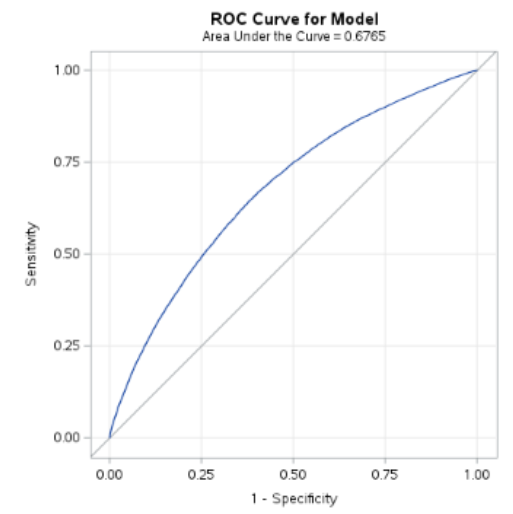

In [ ]:
* Calculate AUC for test data;
proc logistic data=testPredScored;
    model solvedNumeric(event='1') = predProb;
    roc pred=predProb;
    ods output ROCAssociation=testAUC;
    title "ROC Analysis for Logistic Regression Test Data";
run;

## Classification tree

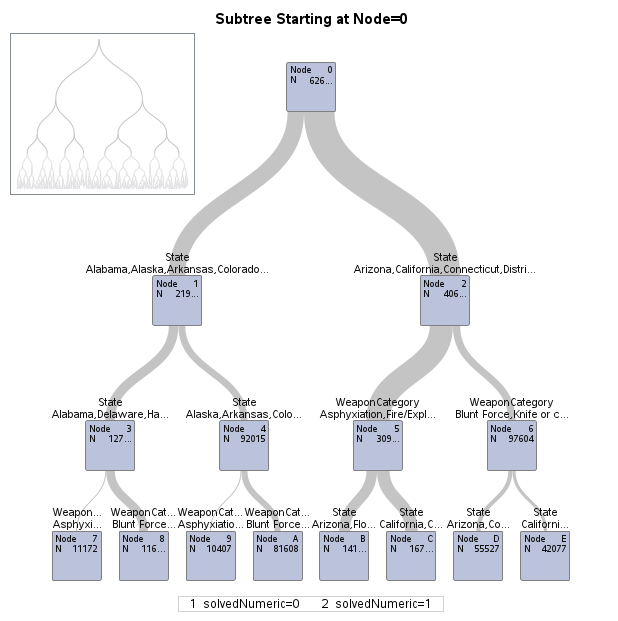

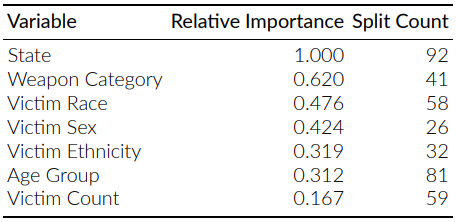

In [ ]:
*CLASSIFICATION TREE;

* Build classification tree model;
proc hpsplit data=training seed=12345 maxdepth=10;
   class solvedNumeric VicSex VicRace WeaponCategory VicEthnic VicAgeGroup State;
   model solvedNumeric (event='1') = VicAgeGroup VicSex VicRace WeaponCategory VicEthnic VicCount State;
   grow entropy;
   output out=fullTreePred;
   code file='/home/u64128910/AMA3011/full_tree_model.sas'; 
   rules file='/home/u64128910/AMA3011/full_tree_rules.txt';
   title "Building Classification Tree Model";
run;

* Apply classification tree model to test data;
data testFullPred;
   set test;
   %include "/home/u64128910/AMA3011/full_tree_model.sas";
run;

* Prepare predictions for evaluation;
data homicidePredFull;
   set testFullPred;
   Actual    = solvedNumeric;
   Predicted = (P_solvedNumeric1 >= 0.65);
   keep Actual Predicted;
run;

## Classification tree: confusion matrices

In [ ]:
* Confusion matrix for classification tree (test data);
title "Confusion Matrix - Classification Tree (Test Data) - Cutoff 0.65";
proc freq data=homicidePredFull;
   tables Actual*Predicted / norow nocol nopct;
run;

* Prepare training predictions for evaluation;
data trainFullPred;
   set fullTreePred;
   Actual = solvedNumeric;
   Predicted = (P_solvedNumeric1 >= 0.65);
   keep Actual Predicted;
run;

* Confusion matrix for classification tree (training data);
title "Confusion Matrix - Classification Tree (Training Data) - Cutoff 0.65";
proc freq data=trainFullPred;
   tables Actual*Predicted / norow nocol nopct;
run;

Confusion matrix, test data, cutoff 0.65 (n = 264,278)
                  Predicted
Actual            Not solved   Solved
Not solved            38,396   38,145
Solved                45,755  141,982


## Classification tree: AUC

In [ ]:
* Calculate AUC for test data from classification tree;
proc logistic data=testFullPred;
   model solvedNumeric(event='1') = P_solvedNumeric1;
   roc pred=P_solvedNumeric1;
   ods output ROCAssociation=treeTestAUC;
   title "ROC Analysis for Classification Tree Test Data";
run;

proc print data=treeTestAUC;
   where ROCModel = 'Model';
   var Area;
   title "Test AUC for Classification Tree Model";
run;

Metric        Training   Test
Accuracy      68.33%     68.26%
Sensitivity   75.64%     75.63%
Specificity   50.40%     50.16%
AUC           0.6825     0.6807


## Utah subset for the R neural network diagram

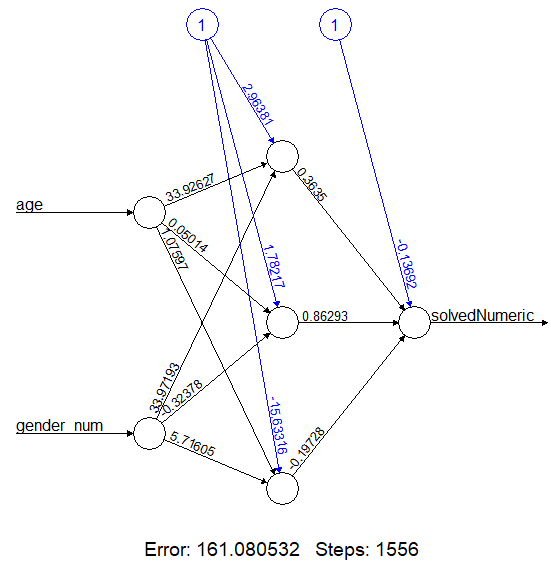

Small neural network drawn in R from the Utah subset (age and gender only)


In [ ]:
* Create subset for Utah analysis;
data ut_subset;
    set AMA3011.SHRv3;
    where State = 'Utah' and VicSex in ('M', 'F') and VicAge ne .;
    solved = solvedNumeric;
    gender = (VicSex = 'F');
    age = VicAge;
run;

* Export Utah subset for external analysis;
proc export data=ut_subset
    outfile="/home/u64128910/AMA3011/utah_subset.csv"
    dbms=csv replace;
    title "Exporting Utah Subset Data for Further Analysis";
run;

## Neural network: split and fit

In [ ]:
*NEURAL NETWORK;

* Split data for neural network training;
proc surveyselect data=AMA3011.SHRv3 method=srs samprate=0.7 out=AllDataNN outall;
    title "Splitting Data for Neural Network (70/30 Split)";
run;

data trainingNN testNN;
    set AllDataNN;
    if selected = 1 then output trainingNN;
    else output testNN;
run;

* Build neural network model;
proc hpneural data=trainingNN;
    input VicAgeGroup VicSex VicRace WeaponCategory VicEthnic VicCount State / level=nom; 
    target solvedNumeric / level=nom;                       
    hidden 5;                                               
    train outmodel=neural_model maxiter=100;
    score out=scores_training_predictions;
    id id; 
    title "Building Neural Network Model";
run;

* Apply neural network model to test data;
proc hpneural data=testNN;
   score model=neural_model out=scores_test_predictions;
   id id; 
   title "Scoring Neural Network Model on Test Data";
run;

## Neural network: merge the predictions

In [ ]:
* Sort datasets for merging;
proc sort data=trainingNN; 
    by id;
run;

proc sort data=scores_training_predictions; 
    by id;
run;

proc sort data=testNN; 
    by id;
run;

proc sort data=scores_test_predictions; 
    by id;
run;

* Merge neural network predictions with training data;
data training_combined;
    merge trainingNN(in=a) scores_training_predictions(in=b);
    by id;  
    if a; 
run;

* Merge neural network predictions with test data;
data test_combined;
    merge testNN(in=a) scores_test_predictions(in=b);
    by id;  
    if a; 
run;

* Convert probabilities to classifications for training data;
data training_combinedv1;
    set training_combined;
    if P_solvedNumeric1 > 0.65 then I_solvedNumeric = 1; 
    else I_solvedNumeric = 0; 
run;

* Convert probabilities to classifications for test data;
data test_combinedv1;
    set test_combined;
    if P_solvedNumeric1 > 0.65 then I_solvedNumeric = 1;  
    else I_solvedNumeric = 0; 
run;

## Neural network: confusion matrices

In [ ]:
* Confusion matrix for neural network training data;
proc freq data=training_combinedv1;
    tables solvedNumeric*I_solvedNumeric / norow nocol nopct;
    title "Confusion Matrix for Training Data (Neural Network)";
run;

* Confusion matrix for neural network test data;
proc freq data=test_combinedv1;
    tables solvedNumeric*I_solvedNumeric / norow nocol nopct;
    title "Confusion Matrix for Test Data (Neural Network)";
run;

Confusion matrix, test data, cutoff 0.65 (n = 264,278)
                  Predicted
Actual            Not solved   Solved
Not solved            39,225   37,376
Solved                46,440  141,237


## Neural network: AUC

In [ ]:
* Calculate AUC for neural network training data;
proc logistic data=training_combinedv1;
    model solvedNumeric(event='1') = P_solvedNumeric1;
    output out=training_auc predicted=prob;
    title "ROC Analysis for Neural Network Training Data";
run;

proc roccurve data=training_auc;
    roc 'Training AUC' prob / event=1;
    title "ROC Curve - Neural Network Training Data";
run;

* Calculate AUC for neural network test data;
proc logistic data=test_combinedv1;
    model solvedNumeric(event='1') = P_solvedNumeric1;
    output out=test_auc predicted=prob;
    title "ROC Analysis for Neural Network Test Data";
run;

proc roccurve data=test_auc;
    roc 'Test AUC' prob / event=1;
    title "ROC Curve - Neural Network Test Data";
run;

Metric        Training   Test
Accuracy      68.34%     68.28%
Sensitivity   75.39%     75.26%
Specificity   51.06%     51.21%
AUC           0.691      0.690

Model comparison, test data, cutoff 0.65
Model                 Accuracy  Sensitivity  Specificity  AUC
Logistic regression   67.8%     75.1%        49.8%        0.677
Classification tree   68.3%     75.6%        50.2%        0.681
Neural network        68.3%     75.3%        51.2%        0.690
